# Bài 2 (Trang 28) – Bank marketing
Tải `bank_marketing.csv` (dữ liệu bảng trong tài liệu) lên Files của Colab trước khi chạy.

In [1]:
# ===== Câu 1: Nhập dữ liệu và thống kê thông tin cơ bản, xác định loại thuộc tính =====
print("Nguyễn Bình Minh - 6451071047")

import numpy as np
import pandas as pd
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore")
df = pd.read_csv('bank_marketing.csv')
display(df)
df.info()
display(df.describe())
display(df.describe(include='object'))

print('Loại thuộc tính:')
print('- Job, Marial, Default : Nominal')
print('- Education            : Ordinal (basic.4y < basic.9y < high.school < professional.course < university.degree)')
print('- Loan, Subscribe      : Binary (Subscribe là thuộc tính quyết định)')
print('- Duration             : Numeric - Ratio-scaled')
print('- Cons.price.idx       : Numeric - Interval-scaled')

Nguyễn Bình Minh - 6451071047


,Job,Marial,Education,Default,Loan,Duration,Cons.price.idx,Subscribe
0,housemaid,Married,basic.4y,no,no,261,93.994,no
1,services,Married,high.school,unknown,no,149,93.994,no
2,blue-collar,Divorced,basic.4y,unknown,no,1575,93.994,yes
3,admin.,Single,high.school,no,no,338,93.994,no
4,blue-collar,Single,basic.9y,no,no,179,93.994,no
5,services,Married,high.school,no,no,1030,93.994,yes
6,management,Married,high.school,unknown,no,149,NaN,no
7,unemployed,NaN,university.degree,unknown,no,424,93.994,no
8,technician,Married,professional.course,no,no,1623,93.994,yes
9,services,Divorced,high.school,unknown,no,568,93.994,no


<class 'pandas.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Job             16 non-null     str    
 1   Marial          15 non-null     str    
 2   Education       16 non-null     str    
 3   Default         16 non-null     str    
 4   Loan            16 non-null     str    
 5   Duration        16 non-null     int64  
 6   Cons.price.idx  15 non-null     float64
 7   Subscribe       16 non-null     str    
dtypes: float64(1), int64(1), str(6)
memory usage: 1.1 KB


,Duration,Cons.price.idx
count,16.000000,15.000000
mean,677.562500,93.830133
std,493.173258,0.326704
min,149.000000,93.200000
25%,318.750000,93.956000
50%,550.000000,93.994000
75%,1037.250000,93.994000
max,1623.000000,93.994000


,Job,Marial,Education,Default,Loan,Subscribe
count,16,15,16,16,16,16
unique,10,3,5,2,2,2
top,services,Married,high.school,no,no,no
freq,4,10,8,11,15,10


Loại thuộc tính:
- Job, Marial, Default : Nominal
- Education            : Ordinal (basic.4y < basic.9y < high.school < professional.course < university.degree)
- Loan, Subscribe      : Binary (Subscribe là thuộc tính quyết định)
- Duration             : Numeric - Ratio-scaled
- Cons.price.idx       : Numeric - Interval-scaled


In [2]:
# ===== Câu 2: Thuộc tính có giá trị rỗng / không xác định =====
print("Nguyễn Bình Minh - 6451071047")

total = df.isnull().sum().sort_values(ascending=False)
percent = round(df.isnull().sum() / df.isnull().count() * 100, 1)
missing_data = pd.concat([total, percent], axis=1, keys=['Total', '%'])
display(missing_data.sort_values('Total', ascending=False).head(5))

print("Số giá trị 'unknown' mỗi cột:")
print((df == 'unknown').sum(), '\n')
print(df['Job'].value_counts())

print('Nhận xét:')
print('- Marial và Cons.price.idx mỗi cột thiếu 1 giá trị (6.2%).')
print("- Default có 5 giá trị 'unknown' (thông tin không xác định).")
print("- Job có 'Retired' viết hoa khác các giá trị còn lại -> dữ liệu nhiễu.")

Nguyễn Bình Minh - 6451071047


,Total,%
Marial,1,6.2
Cons.price.idx,1,6.2
Education,0,0.0
Job,0,0.0
Default,0,0.0


Số giá trị 'unknown' mỗi cột:
Job               0
Marial            0
Education         0
Default           5
Loan              0
Duration          0
Cons.price.idx    0
Subscribe         0
dtype: int64 

Job
services         4
blue-collar      3
technician       2
housemaid        1
admin.           1
management       1
unemployed       1
self-employed    1
entrepreneur     1
Retired          1
Name: count, dtype: int64
Nhận xét:
- Marial và Cons.price.idx mỗi cột thiếu 1 giá trị (6.2%).
- Default có 5 giá trị 'unknown' (thông tin không xác định).
- Job có 'Retired' viết hoa khác các giá trị còn lại -> dữ liệu nhiễu.


Nguyễn Bình Minh - 6451071047


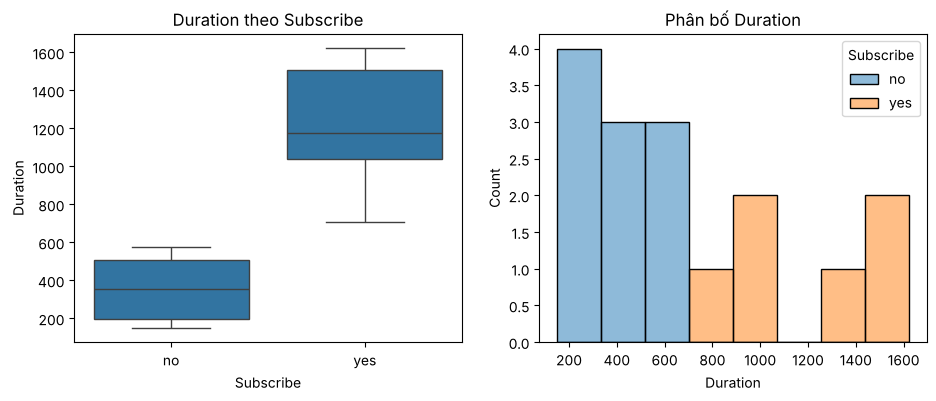

,count,mean,std,min,25%,50%,75%,max
Subscribe,,,,,,,,
no,10.0,355.200000,168.560441,149.0,199.50,357.0,505.0,576.0
yes,6.0,1214.833333,352.547538,705.0,1037.25,1178.0,1505.5,1623.0


Nhận xét:
- Nhóm đăng ký (yes) có Duration trung bình ~1215 giây (thấp nhất 705).
- Nhóm không đăng ký chỉ trung bình ~355 giây (cao nhất 576).
- Liên hệ càng lâu thì khả năng đăng ký càng cao -> Duration là thuộc tính quan trọng.


In [3]:
# ===== Câu 3: Liên quan giữa Duration và Subscribe =====
print("Nguyễn Bình Minh - 6451071047")

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(11, 4))
sns.boxplot(x='Subscribe', y='Duration', data=df, ax=axes[0])
axes[0].set_title('Duration theo Subscribe')
sns.histplot(data=df, x='Duration', hue='Subscribe', bins=8, ax=axes[1])
axes[1].set_title('Phân bố Duration')
plt.show()
display(df.groupby('Subscribe')['Duration'].describe())

print('Nhận xét:')
print('- Nhóm đăng ký (yes) có Duration trung bình ~1215 giây (thấp nhất 705).')
print('- Nhóm không đăng ký chỉ trung bình ~355 giây (cao nhất 576).')
print('- Liên hệ càng lâu thì khả năng đăng ký càng cao -> Duration là thuộc tính quan trọng.')

Nguyễn Bình Minh - 6451071047


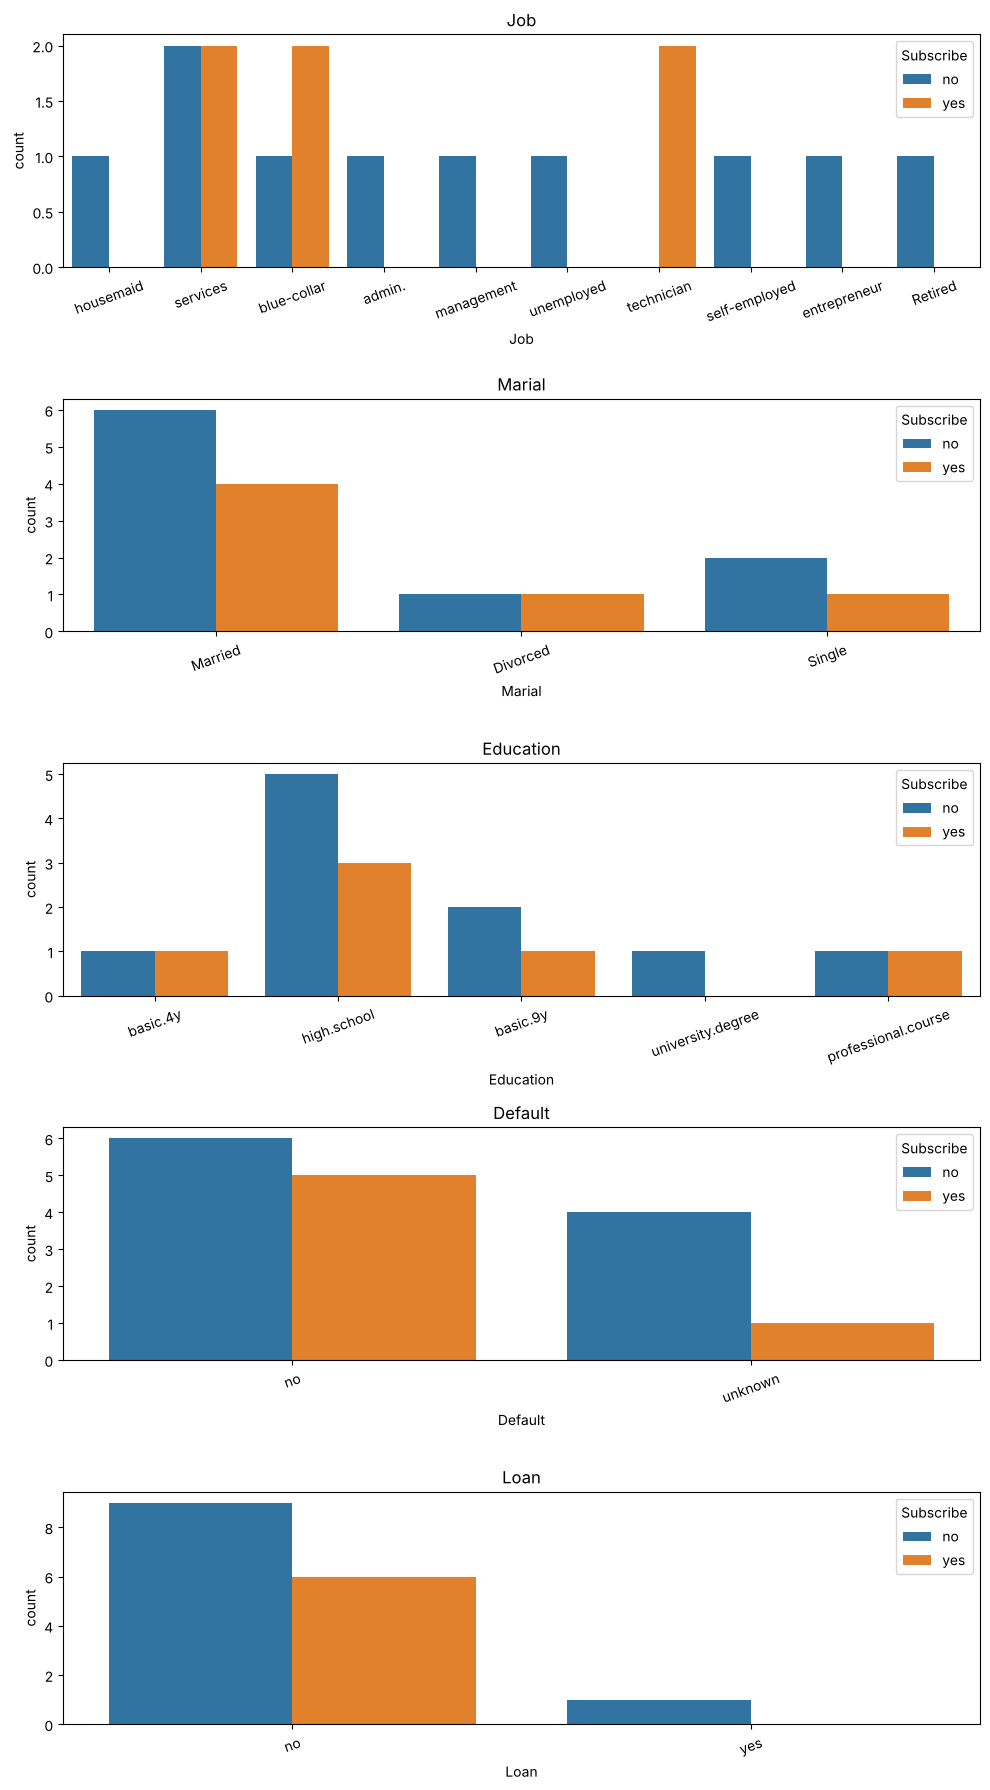

Marial
Divorced    0.50
Married     0.40
Single      0.33
Name: sub, dtype: float64 

Education
basic.4y               0.50
basic.9y               0.33
high.school            0.38
professional.course    0.50
university.degree      0.00
Name: sub, dtype: float64 

Default
no         0.45
unknown    0.20
Name: sub, dtype: float64 

Loan
no     0.4
yes    0.0
Name: sub, dtype: float64 

Nhận xét:
(Mẫu chỉ có 16 dòng nên kết luận mang tính tham khảo)
- Job: technician (2/2) và blue-collar (2/3) đăng ký nhiều; services 2/4; các nghề khác không đăng ký.
- Marial: Divorced (50%) > Married (40%) > Single (33%).
- Education: basic.4y và professional.course đăng ký cao nhất (50%).
- Default = no đăng ký nhiều hơn (45%) so với unknown (20%).
- Người đang có khoản vay (Loan = yes, 1 mẫu) không đăng ký.


In [4]:
# ===== Câu 4: Liên quan giữa Job, Marial, Education, Default, Loan với Subscribe =====
print("Nguyễn Bình Minh - 6451071047")

cols = ['Job', 'Marial', 'Education', 'Default', 'Loan']
fig, axes = plt.subplots(nrows=len(cols), ncols=1, figsize=(10, 18))
for ax, col in zip(axes, cols):
    sns.countplot(x=col, hue='Subscribe', data=df, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

d = df.copy()
d['sub'] = (d['Subscribe'] == 'yes').astype(int)
for col in ['Marial', 'Education', 'Default', 'Loan']:
    print(d.groupby(col)['sub'].mean().round(2), '\n')

print('Nhận xét:')
print('(Mẫu chỉ có 16 dòng nên kết luận mang tính tham khảo)')
print('- Job: technician (2/2) và blue-collar (2/3) đăng ký nhiều; services 2/4; các nghề khác không đăng ký.')
print('- Marial: Divorced (50%) > Married (40%) > Single (33%).')
print('- Education: basic.4y và professional.course đăng ký cao nhất (50%).')
print('- Default = no đăng ký nhiều hơn (45%) so với unknown (20%).')
print('- Người đang có khoản vay (Loan = yes, 1 mẫu) không đăng ký.')

In [5]:
# ===== Câu 5: Tiền xử lý dữ liệu thiếu, nhiễu và xóa thuộc tính không cần thiết =====
print("Nguyễn Bình Minh - 6451071047")

# Dữ liệu nhiễu: đưa chuỗi về chữ thường ('Retired' -> 'retired')
for col in ['Job', 'Marial', 'Education', 'Default', 'Loan', 'Subscribe']:
    df[col] = df[col].str.strip().str.lower()

# Marial (categorical): điền bằng mode
common_value = df['Marial'].mode()[0]
print('Mode của Marial:', common_value)
df['Marial'] = df['Marial'].fillna(common_value)

# Cons.price.idx (số): điền bằng trung vị
df['Cons.price.idx'] = df['Cons.price.idx'].fillna(df['Cons.price.idx'].median())
print(df['Cons.price.idx'].describe(), '\n')

# Cons.price.idx chỉ có 3 giá trị, gần như hằng số -> không giúp phân biệt -> xóa
df = df.drop(['Cons.price.idx'], axis=1)
df.info()
print(df.isnull().sum())

Nguyễn Bình Minh - 6451071047
Mode của Marial: married
count    16.000000
mean     93.840375
std       0.318274
min      93.200000
25%      93.975000
50%      93.994000
75%      93.994000
max      93.994000
Name: Cons.price.idx, dtype: float64 

<class 'pandas.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Job        16 non-null     str  
 1   Marial     16 non-null     str  
 2   Education  16 non-null     str  
 3   Default    16 non-null     str  
 4   Loan       16 non-null     str  
 5   Duration   16 non-null     int64
 6   Subscribe  16 non-null     str  
dtypes: int64(1), str(6)
memory usage: 1.0 KB
Job          0
Marial       0
Education    0
Default      0
Loan         0
Duration     0
Subscribe    0
dtype: int64


In [6]:
# ===== Câu 6: Biến đổi thuộc tính và chuẩn hóa Min-max =====
print("Nguyễn Bình Minh - 6451071047")

# a) Binary / nominal ít giá trị -> số
yes_no = {"no": 0, "yes": 1}
df['Subscribe'] = df['Subscribe'].map(yes_no)
df['Loan'] = df['Loan'].map(yes_no)
df['Default'] = df['Default'].map({"no": 0, "unknown": 1, "yes": 2})
df['Marial'] = df['Marial'].map({"single": 0, "married": 1, "divorced": 2})

# b) Education có thứ tự -> mã hóa theo cấp bậc
education = {"basic.4y": 0, "basic.9y": 1, "high.school": 2,
             "professional.course": 3, "university.degree": 4}
df['Education'] = df['Education'].map(education)

# c) Job nominal nhiều giá trị -> One-hot Encoding
df = pd.get_dummies(df, columns=['Job'], prefix='job', dtype=int)

# d) Chia Duration thành 4 nhóm cân bằng
df['duration_group'] = pd.qcut(df['Duration'], q=4, labels=[0, 1, 2, 3]).astype(int)

# e) Chuẩn hóa Duration bằng Min-max
dmin, dmax = df['Duration'].min(), df['Duration'].max()
df['duration_norm'] = ((df['Duration'] - dmin) / (dmax - dmin)).round(4)

display(df)

Nguyễn Bình Minh - 6451071047


,Marial,Education,Default,Loan,Duration,Subscribe,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_technician,job_unemployed,duration_group,duration_norm
0,1,0,0,0,261,0,0,0,0,1,0,0,0,0,0,0,0,0.0760
1,1,2,1,0,149,0,0,0,0,0,0,0,0,1,0,0,0,0.0000
2,2,0,1,0,1575,1,0,1,0,0,0,0,0,0,0,0,3,0.9674
3,0,2,0,0,338,0,1,0,0,0,0,0,0,0,0,0,1,0.1282
4,0,1,0,0,179,0,0,1,0,0,0,0,0,0,0,0,0,0.0204
5,1,2,0,0,1030,1,0,0,0,0,0,0,0,1,0,0,2,0.5977
6,1,2,1,0,149,0,0,0,0,0,1,0,0,0,0,0,0,0.0000
7,1,4,1,0,424,0,0,0,0,0,0,0,0,0,0,1,1,0.1866
8,1,3,0,0,1623,1,0,0,0,0,0,0,0,0,1,0,3,1.0000
9,2,2,1,0,568,0,0,0,0,0,0,0,0,1,0,0,2,0.2843
